![Preprocessing flowchart](../flowchart/BearKillings_Flowchart_Aguila_Solis.png)

# **Data Preprocessing Project: North American Bear Killings**
## Data Cleaning, Feature Preparation, Validation, and Visualization

**Dataset:** `north_america_bear_killings.csv`  
**Project focus:** Exploring recorded fatal bear-attack incidents in North America through careful data preprocessing.

### Project objectives
1. Inspect the dataset's structure, data types, missing values, and duplicate records.
2. Clean text fields and convert columns to suitable data types.
3. Detect unusual numeric values without automatically deleting potentially meaningful historical cases.
4. Create useful date-based features, encode selected categorical variables, and scale a numerical feature for modeling.
5. Save and validate the cleaned dataset and create exactly ten meaningful visualizations.

> **Data provenance note:** The uploaded CSV is the data source used in this notebook. The file itself does not include a verifiable publisher or source URL, so no external origin is assumed. The descriptive text may contain citations or formatting inherited from its original compilation.

## Step 1 — Load the dataset

**Flowchart reference: step 1.** Upload the supplied CSV in Google Colab. The code searches for the expected filename among uploaded files and also supports a local file path when testing outside Colab.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
try:
    from google.colab import files
except ImportError:
    files = None

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

expected_filename = "north_america_bear_killings.csv"

# In Colab, upload the CSV if it is not already in the working directory.
if not os.path.exists(expected_filename) and os.path.exists("/mnt/data/north_america_bear_killings.csv"):
    expected_filename = "/mnt/data/north_america_bear_killings.csv"

if not os.path.exists(expected_filename):
    if files is None:
        raise FileNotFoundError("Place north_america_bear_killings.csv in the working directory.")
    uploaded = files.upload()
    csv_candidates = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_candidates:
        raise FileNotFoundError("Please upload the north_america_bear_killings.csv file.")
    expected_filename = next(
        (name for name in csv_candidates if os.path.basename(name) == "north_america_bear_killings.csv"),
        csv_candidates[0]
    )

df_raw = pd.read_csv(expected_filename)
df = df_raw.copy()

print(f"Loaded file: {expected_filename}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Saving north_america_bear_killings.csv to north_america_bear_killings.csv
Loaded file: north_america_bear_killings.csv
Rows: 166 | Columns: 14


,Name,age,gender,Date,Month,Year,Type,Location,Description,Type of bear,Hunter,Grizzly,Hikers,Only one killed
0,Erin Johnson,27,female,2017-06-19,6,2017,Wild,"Pogo mine, Alaska","Johnson, a contract employee for Pogo Mine, wa...",Black bear,0,0,0,1
1,Patrick Cooper,16,male,2017-06-18,6,2017,Wild,"Indian, Alaska",Cooper was chased and mauled by a bear while r...,Black bear,0,0,0,1
2,Daniel Ward O'Connor,27,male,2015-05-10,5,2015,Wild,"near Mackenzie, British Columbia",Ward was killed by a bear while he slept near ...,Black bear,0,0,0,1
3,Darsh Patel,22,male,2014-09-21,9,2014,Wild,"near West Milford, New Jersey",Patel was about to begin hiking with four frie...,Black bear,0,0,1,1
4,Lorna Weafer,36,female,2014-05-07,5,2014,Wild,"near Fort McMurray, Alberta","Weafer, a Suncor worker was attacked at the re...",Black bear,0,0,0,1


## Step 2 — Inspect the data

**Flowchart reference: step 2.** Review the first and last records, dimensions, column names, data types, summary statistics, and distinct-value counts. This helps identify text stored as numbers and columns that need cleaning.

In [2]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

print("\nNumeric summary:")
display(df.describe(include="all").T)

print("\nUnique values per column:")
display(df.nunique(dropna=False).rename("unique_values").to_frame())

print("\nDataset information:")
df.info()

Dataset shape: (166, 14)

Column names:
['Name', ' age', 'gender', 'Date', 'Month', 'Year', 'Type', 'Location', 'Description', 'Type of bear', 'Hunter', 'Grizzly', 'Hikers', 'Only one killed']

Data types:


,data_type
Name,object
age,object
gender,object
Date,object
Month,int64
Year,int64
Type,object
Location,object
Description,object
Type of bear,object



Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,166,166,Erin Johnson,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,166,68,40,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,165,4,male,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,166,150,1978-05-13,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,166.0,NaN,NaN,NaN,7.698795,2.189423,1.0,6.0,8.0,9.0,12.0
Year,166.0,NaN,NaN,NaN,1981.313253,28.868323,1901.0,1967.0,1987.0,2005.0,2018.0
Type,166,2,Wild,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,166,132,"Glacier National Park, Montana",10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,166,152,The three boys were stalked and killed while f...,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type of bear,166,3,Brown bear,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique values per column:


,unique_values
Name,166
age,68
gender,5
Date,150
Month,12
Year,75
Type,2
Location,132
Description,152
Type of bear,3



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Name             166 non-null    object
 1    age             166 non-null    object
 2   gender           165 non-null    object
 3   Date             166 non-null    object
 4   Month            166 non-null    int64 
 5   Year             166 non-null    int64 
 6   Type             166 non-null    object
 7   Location         166 non-null    object
 8   Description      166 non-null    object
 9   Type of bear     166 non-null    object
 10  Hunter           166 non-null    int64 
 11  Grizzly          166 non-null    int64 
 12  Hikers           166 non-null    int64 
 13  Only one killed  166 non-null    int64 
dtypes: int64(6), object(8)
memory usage: 18.3+ KB


## Step 3 — Check missing and blank values

**Flowchart decision:** Are there missing values or blank text fields?  
- **YES:** Standardize whitespace, convert blank text to missing values, and fill the one missing gender value with `Unknown`. Keep missingness explicit rather than guessing a person's gender.  
- **NO:** Preserve the values as they are.

The cleaning step will be applied after making a copy, so the original imported data remains available for comparison.

In [3]:
# Strip leading/trailing whitespace and normalize non-breaking spaces in text columns.
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    df[col] = (
        df[col].astype("string")
        .str.replace("\\u00a0", " ", regex=False)
        .str.strip()
    )
    df[col] = df[col].replace("", pd.NA)

print("Missing values before filling:")
display(df.isna().sum().rename("missing_count").to_frame())

# Fill only the gender field with an explicit category; do not invent other details.
if "gender" in df.columns:
    df["gender"] = df["gender"].fillna("Unknown")

print("\nMissing values after the planned fill:")
display(df.isna().sum().rename("missing_count").to_frame())

Missing values before filling:


,missing_count
Name,0
age,0
gender,1
Date,0
Month,0
Year,0
Type,0
Location,0
Description,0
Type of bear,0



Missing values after the planned fill:


,missing_count
Name,0
age,0
gender,0
Date,0
Month,0
Year,0
Type,0
Location,0
Description,0
Type of bear,0


## Step 3 — Check and handle duplicate rows

**Flowchart decision:** Are there exact duplicate records?  
- **YES:** Remove exact duplicate rows while keeping the first copy, and report the number removed.  
- **NO:** Keep all rows.

Only exact row duplicates are removed. Similar names or incidents are not merged automatically because that would require additional source verification.

In [4]:
duplicates_before = int(df.duplicated().sum())
rows_before = len(df)
print("Exact duplicate rows:", duplicates_before)

if duplicates_before > 0:
    df = df.drop_duplicates().copy()

print("Rows before:", rows_before)
print("Rows after :", len(df))
print("Rows removed:", rows_before - len(df))

Exact duplicate rows: 0
Rows before: 166
Rows after : 166
Rows removed: 0


## Step 5 — Correct data types and standardize column names

**Flowchart reference: step 5 (fix data types).** Standardize column labels, convert age to numeric, parse the date field, and derive consistent month/year values from the parsed date where possible. The dataset contains a leading space in the `age` column name, so column names are stripped. Invalid conversions remain missing and are reported rather than silently guessed.

In [5]:
# Normalize column labels and the age field name.
df.columns = df.columns.astype(str).str.strip()
if "age" not in df.columns and "age" in [c.lower() for c in df.columns]:
    df = df.rename(columns={next(c for c in df.columns if c.lower() == "age"): "age"})

# Convert age to numeric; invalid values become missing.
if "age" in df.columns:
    df["age"] = pd.to_numeric(df["age"], errors="coerce")

# Parse incident date with invalid dates set to NaT.
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Use the parsed date to correct month/year if they disagree or are missing.
if "Date" in df.columns:
    valid_date = df["Date"].notna()
    if "Month" in df.columns:
        df.loc[valid_date, "Month"] = df.loc[valid_date, "Date"].dt.month
    if "Year" in df.columns:
        df.loc[valid_date, "Year"] = df.loc[valid_date, "Date"].dt.year

for col in ["Month", "Year", "Hunter", "Grizzly", "Hikers", "Only one killed"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

print(df.dtypes)
print("\nMissing values after type conversion:")
display(df.isna().sum().rename("missing_count").to_frame())

Name               string[python]
age                         Int64
gender             string[python]
Date               datetime64[ns]
Month                       Int64
Year                        Int64
Type               string[python]
Location           string[python]
Description        string[python]
Type of bear       string[python]
Hunter                      Int64
Grizzly                     Int64
Hikers                      Int64
Only one killed             Int64
dtype: object

Missing values after type conversion:


,missing_count
Name,0
age,5
gender,0
Date,0
Month,0
Year,0
Type,0
Location,0
Description,0
Type of bear,0


## Step 3 — Detect and treat numeric outliers

**Flowchart decision:** Are there potential outliers in age? The interquartile range (IQR) rule flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Because these records describe real historical incidents, an unusual age is not automatically an error. We will flag and inspect outliers, but retain the original rows unless a value is demonstrably invalid.

In [6]:
def iqr_outlier_summary(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if values.empty:
        return {"Q1": np.nan, "Q3": np.nan, "IQR": np.nan,
                "lower_fence": np.nan, "upper_fence": np.nan, "outlier_count": 0}
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    return {"Q1": q1, "Q3": q3, "IQR": iqr,
            "lower_fence": lower, "upper_fence": upper, "outlier_count": count}

if "age" in df.columns:
    age_outlier_info = iqr_outlier_summary(df["age"])
    display(pd.DataFrame([age_outlier_info], index=["age"]).T.rename(columns={0: "value"}))
    low, high = age_outlier_info["lower_fence"], age_outlier_info["upper_fence"]
    df["age_outlier_flag"] = df["age"].notna() & ((df["age"] < low) | (df["age"] > high))
    print("Potential age outliers flagged:", int(df["age_outlier_flag"].sum()))
    print("Rows retained; outlier flag is for review, not automatic deletion.")
else:
    print("Age column not available; numeric outlier detection skipped.")

,age
Q1,22.0
Q3,52.0
IQR,30.0
lower_fence,-23.0
upper_fence,97.0
outlier_count,0.0


Potential age outliers flagged: 0
Rows retained; outlier flag is for review, not automatic deletion.


## Added beyond the flowchart — Feature engineering

**Added beyond the flowchart.** Create features that can be derived directly from the recorded date: `incident_month`, `incident_year`, `incident_decade`, and `incident_season`. The season labels use Northern Hemisphere meteorological seasons. These features are useful for examining when incidents were recorded. The original date and month/year columns are retained for traceability.

In [7]:
if "Date" in df.columns:
    df["incident_month"] = df["Date"].dt.month.astype("Int64")
    df["incident_year"] = df["Date"].dt.year.astype("Int64")
    df["incident_decade"] = ((df["Date"].dt.year // 10) * 10).astype("Int64")

    season_map = {
        12: "Winter", 1: "Winter", 2: "Winter",
        3: "Spring", 4: "Spring", 5: "Spring",
        6: "Summer", 7: "Summer", 8: "Summer",
        9: "Autumn", 10: "Autumn", 11: "Autumn"
    }
    df["incident_season"] = df["Date"].dt.month.map(season_map).astype("string")

print("Feature engineering completed where source dates were valid.")
display(df[[c for c in ["Date", "incident_month", "incident_year", "incident_decade", "incident_season"] if c in df.columns]].head())

Feature engineering completed where source dates were valid.


,Date,incident_month,incident_year,incident_decade,incident_season
0,2017-06-19,6,2017,2010,Summer
1,2017-06-18,6,2017,2010,Summer
2,2015-05-10,5,2015,2010,Spring
3,2014-09-21,9,2014,2010,Autumn
4,2014-05-07,5,2014,2010,Spring


## Step 7 — Encode categorical variables

**Flowchart reference: step 7 (encode categorical columns).** Keep the cleaned dataset human-readable, and create a separate model-ready table with one-hot encoded categories. Encoding is limited to low-cardinality descriptive columns (`gender`, `Type`, and `Type of bear`) when present. Names, locations, and narrative descriptions are not encoded because they are high-cardinality text fields and are not necessary for the core incident summaries.

In [8]:
df_clean = df.copy()

categorical_for_encoding = [c for c in ["gender", "Type", "Type of bear"] if c in df_clean.columns]
df_model = df_clean.copy()

# Exclude free-text identifiers/narratives and raw datetime from the model-ready feature matrix.
exclude_from_model = [c for c in ["Name", "Location", "Description", "Date"] if c in df_model.columns]
df_model = df_model.drop(columns=exclude_from_model)

df_model = pd.get_dummies(
    df_model,
    columns=categorical_for_encoding,
    dummy_na=False,
    dtype=int
)

print("Categorical columns encoded:", categorical_for_encoding)
print("Model-ready shape:", df_model.shape)
display(df_model.head())

Categorical columns encoded: ['gender', 'Type', 'Type of bear']
Model-ready shape: (166, 20)


,age,Month,Year,Hunter,Grizzly,Hikers,Only one killed,age_outlier_flag,incident_month,incident_year,incident_decade,incident_season,gender_Unknown,gender_female,gender_male,Type_Captive,Type_Wild,Type of bear_Black bear,Type of bear_Brown bear,Type of bear_Polar Bear
0,27,6,2017,0,0,0,1,False,6,2017,2010,Summer,0,1,0,0,1,1,0,0
1,16,6,2017,0,0,0,1,False,6,2017,2010,Summer,0,0,1,0,1,1,0,0
2,27,5,2015,0,0,0,1,False,5,2015,2010,Spring,0,0,1,0,1,1,0,0
3,22,9,2014,0,0,1,1,False,9,2014,2010,Autumn,0,0,1,0,1,1,0,0
4,36,5,2014,0,0,0,1,False,5,2014,2010,Spring,0,1,0,0,1,1,0,0


## Step 8 — Scale numerical variables where appropriate

**Flowchart reference: step 8 (scale numerical features).** Standardize `age` in the model-ready dataset when it contains at least two valid values. Scaling is useful for algorithms sensitive to feature magnitude, but it is not needed for descriptive charts or tree-based models. The readable cleaned dataset keeps age in its original units. Missing ages are left missing rather than imputed without evidence.

In [9]:
scale_columns = []
if "age" in df_model.columns and df_model["age"].notna().sum() >= 2:
    scale_columns = ["age"]
    scaler = StandardScaler()
    valid_mask = df_model["age"].notna()
    df_model.loc[valid_mask, "age_scaled"] = scaler.fit_transform(
        df_model.loc[valid_mask, ["age"]]
    ).ravel()
    print("Created age_scaled using StandardScaler. Original age column remains unchanged.")
else:
    print("Scaling skipped: insufficient valid age values.")

print("Scaled columns created:", ["age_scaled"] if "age_scaled" in df_model.columns else [])

Created age_scaled using StandardScaler. Original age column remains unchanged.
Scaled columns created: ['age_scaled']


## Step 9 — Save the cleaned dataset

**Flowchart reference: step 9 (save the cleaned dataset).** Save the readable cleaned data for analysis and a separate encoded/model-ready dataset. The first file preserves meaningful labels and the original incident details; the second is intended for selected machine-learning workflows. Download links are shown in Google Colab.

In [10]:
cleaned_filename = "cleaned_north_america_bear_killings.csv"
model_filename = "model_ready_bear_killings.csv"

df_clean.to_csv(cleaned_filename, index=False)
df_model.to_csv(model_filename, index=False)

print("Saved:", cleaned_filename, f"({os.path.getsize(cleaned_filename):,} bytes)")
print("Saved:", model_filename, f"({os.path.getsize(model_filename):,} bytes)")

# Uncomment either line in Colab if you want to download immediately.
# files.download(cleaned_filename)
# files.download(model_filename)

Saved: cleaned_north_america_bear_killings.csv (59,172 bytes)
Saved: model_ready_bear_killings.csv (13,271 bytes)


## Added beyond the flowchart — Validate the final dataset

**Added beyond the flowchart.** Confirm the saved dataset can be read back, compare row counts, inspect remaining missing values, check duplicate rows, and verify the date and age data types. Missing age/date values, if any, are reported rather than concealed.

In [11]:
validation_df = pd.read_csv(cleaned_filename)
print("Original imported shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)
print("Reloaded CSV shape:", validation_df.shape)
print("Shape matches saved cleaned data:", validation_df.shape == df_clean.shape)
print("Duplicate rows in cleaned data:", int(df_clean.duplicated().sum()))

print("\nMissing values in cleaned data:")
display(df_clean.isna().sum().rename("missing_count").to_frame())

print("\nSelected data types:")
display(df_clean[[c for c in ["age", "Date", "Month", "Year", "gender", "Type", "Type of bear"] if c in df_clean.columns]].dtypes.rename("data_type").to_frame())

Original imported shape: (166, 14)
Cleaned shape: (166, 19)
Reloaded CSV shape: (166, 19)
Shape matches saved cleaned data: True
Duplicate rows in cleaned data: 0

Missing values in cleaned data:


,missing_count
Name,0
age,5
gender,0
Date,0
Month,0
Year,0
Type,0
Location,0
Description,0
Type of bear,0



Selected data types:


,data_type
age,Int64
Date,datetime64[ns]
Month,Int64
Year,Int64
gender,string[python]
Type,string[python]
Type of bear,string[python]


## Step 10 — Visualization loop: create 10 visualizations

The following charts use the cleaned data and actual dataset columns. Each chart has a numbered title, labeled axes, a readable layout, and a short interpretation caption. Counts describe the records in this CSV; they should not be interpreted as population-level risk rates.

In [12]:
# Prepare consistent plotting data.
plot_df = df_clean.copy()
if "gender" in plot_df.columns:
    plot_df["gender"] = plot_df["gender"].fillna("Unknown")
if "Type of bear" in plot_df.columns:
    plot_df["Type of bear"] = plot_df["Type of bear"].fillna("Unknown")
if "Type" in plot_df.columns:
    plot_df["Type"] = plot_df["Type"].fillna("Unknown")

### Visualization 1 — Recorded incidents by bear type

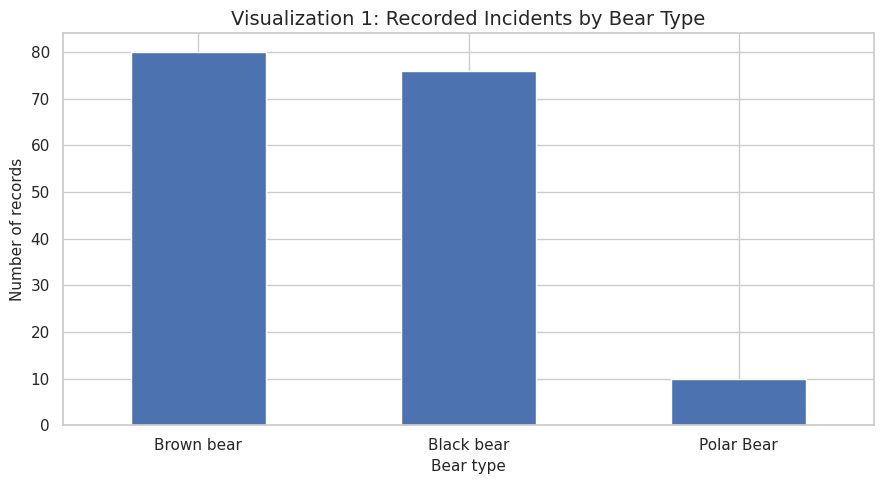

Caption: This chart compares the number of records associated with each bear type in the supplied dataset.


In [13]:
if "Type of bear" in plot_df.columns:
    ax = plot_df["Type of bear"].value_counts().plot(kind="bar", figsize=(9, 5))
    ax.set_title("Visualization 1: Recorded Incidents by Bear Type")
    ax.set_xlabel("Bear type")
    ax.set_ylabel("Number of records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print("Caption: This chart compares the number of records associated with each bear type in the supplied dataset.")
else:
    print("Skipped: Type of bear column is unavailable.")

### Visualization 2 — Incidents by month

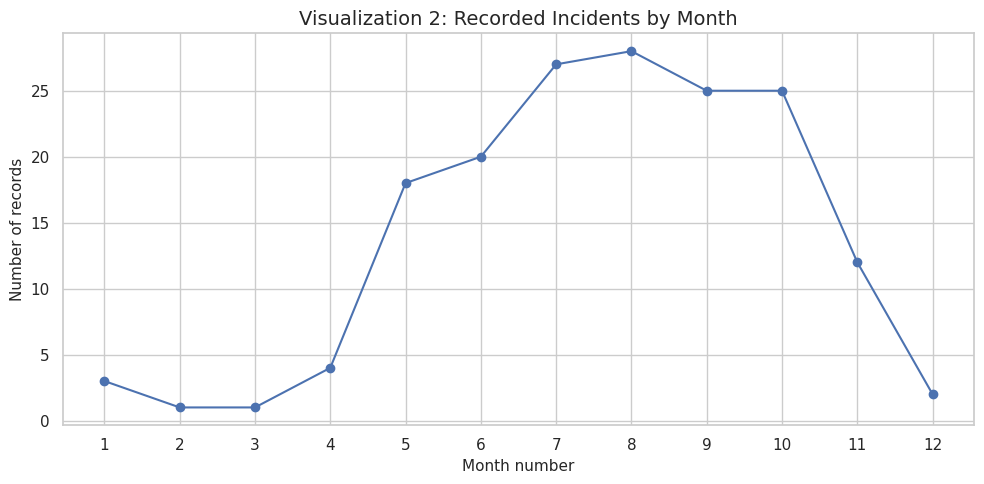

Caption: Monthly counts show how the recorded incidents are distributed across the calendar year.


In [14]:
month_counts = plot_df["incident_month"].dropna().astype(int).value_counts().sort_index() if "incident_month" in plot_df.columns else pd.Series(dtype=int)
if not month_counts.empty:
    ax = month_counts.reindex(range(1, 13), fill_value=0).plot(kind="line", marker="o", figsize=(10, 5))
    ax.set_title("Visualization 2: Recorded Incidents by Month")
    ax.set_xlabel("Month number")
    ax.set_ylabel("Number of records")
    ax.set_xticks(range(1, 13))
    plt.tight_layout()
    plt.show()
    print("Caption: Monthly counts show how the recorded incidents are distributed across the calendar year.")
else:
    print("Skipped: No valid date-derived month values.")

### Visualization 3 — Incidents by year

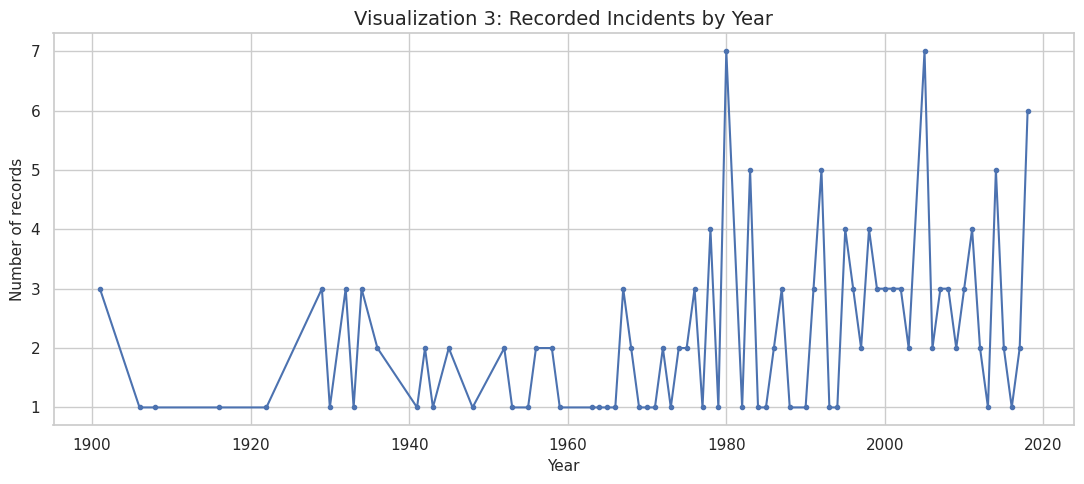

Caption: The year-by-year count reflects the records available in this file and may be affected by historical reporting coverage.


In [15]:
year_counts = plot_df["incident_year"].dropna().astype(int).value_counts().sort_index() if "incident_year" in plot_df.columns else pd.Series(dtype=int)
if not year_counts.empty:
    ax = year_counts.plot(kind="line", marker=".", linewidth=1.5, figsize=(11, 5))
    ax.set_title("Visualization 3: Recorded Incidents by Year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()
    print("Caption: The year-by-year count reflects the records available in this file and may be affected by historical reporting coverage.")
else:
    print("Skipped: No valid date-derived year values.")

### Visualization 4 — Age distribution

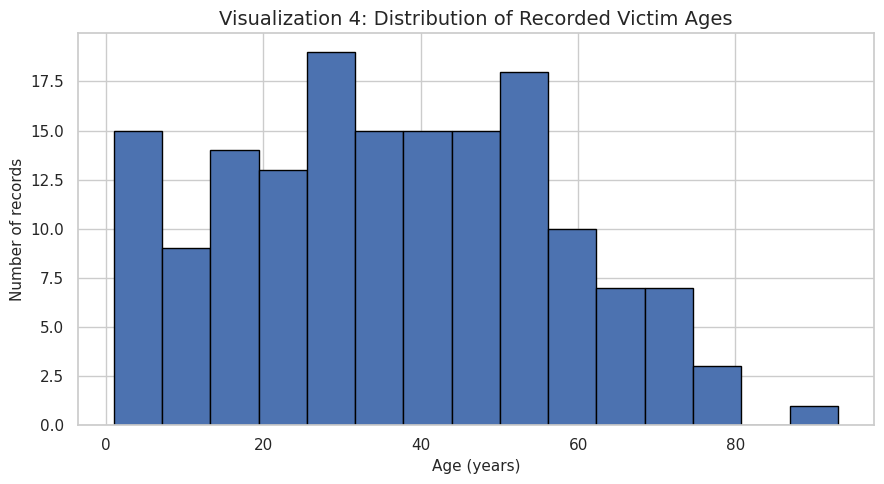

Caption: The histogram summarizes the age distribution among records with a valid numeric age.


In [16]:
ages = pd.to_numeric(plot_df["age"], errors="coerce").dropna() if "age" in plot_df.columns else pd.Series(dtype=float)
if not ages.empty:
    plt.figure(figsize=(9, 5))
    plt.hist(ages.astype(float), bins=15, edgecolor="black")
    plt.title("Visualization 4: Distribution of Recorded Victim Ages")
    plt.xlabel("Age (years)")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()
    print("Caption: The histogram summarizes the age distribution among records with a valid numeric age.")
else:
    print("Skipped: No valid numeric age values.")

### Visualization 5 — Age by bear type

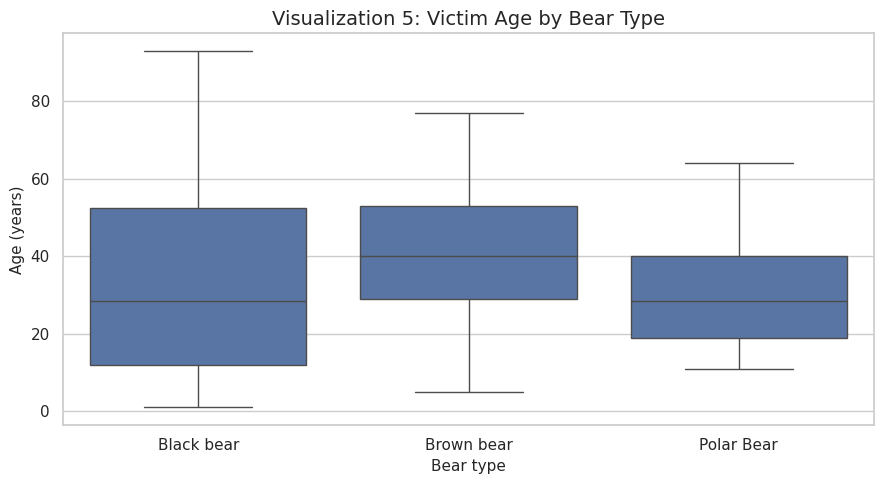

Caption: Box plots compare the median, spread, and potential extreme ages across bear-type categories.


In [17]:
if "age" in plot_df.columns and "Type of bear" in plot_df.columns:
    age_box = plot_df[["age", "Type of bear"]].copy()
    age_box["age"] = pd.to_numeric(age_box["age"], errors="coerce")
    age_box = age_box.dropna()
    if not age_box.empty:
        plt.figure(figsize=(9, 5))
        sns.boxplot(data=age_box, x="Type of bear", y="age")
        plt.title("Visualization 5: Victim Age by Bear Type")
        plt.xlabel("Bear type")
        plt.ylabel("Age (years)")
        plt.tight_layout()
        plt.show()
        print("Caption: Box plots compare the median, spread, and potential extreme ages across bear-type categories.")
    else:
        print("Skipped: No complete age and bear-type pairs.")
else:
    print("Skipped: Required columns unavailable.")

### Visualization 6 — Wild versus captive incidents

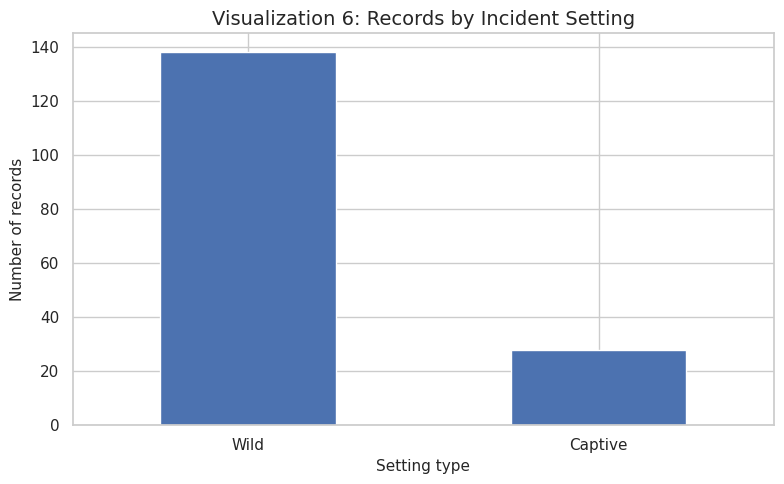

Caption: This chart compares the counts labeled as wild and captive in the supplied data.


In [18]:
if "Type" in plot_df.columns:
    type_counts = plot_df["Type"].value_counts()
    ax = type_counts.plot(kind="bar", figsize=(8, 5))
    ax.set_title("Visualization 6: Records by Incident Setting")
    ax.set_xlabel("Setting type")
    ax.set_ylabel("Number of records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print("Caption: This chart compares the counts labeled as wild and captive in the supplied data.")
else:
    print("Skipped: Type column unavailable.")

### Visualization 7 — Recorded incidents by gender

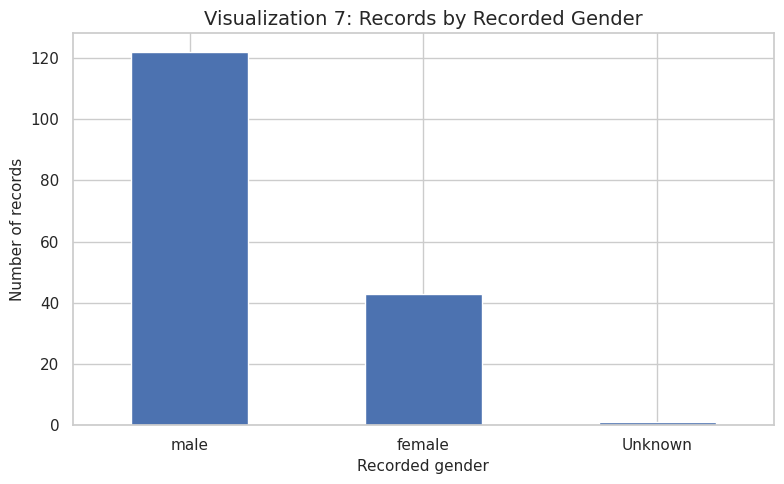

Caption: Counts summarize the gender labels in the records; they do not indicate comparative risk without population and exposure data.


In [19]:
if "gender" in plot_df.columns:
    gender_counts = plot_df["gender"].fillna("Unknown").value_counts()
    ax = gender_counts.plot(kind="bar", figsize=(8, 5))
    ax.set_title("Visualization 7: Records by Recorded Gender")
    ax.set_xlabel("Recorded gender")
    ax.set_ylabel("Number of records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print("Caption: Counts summarize the gender labels in the records; they do not indicate comparative risk without population and exposure data.")
else:
    print("Skipped: gender column unavailable.")

### Visualization 8 — Monthly incidents by bear type

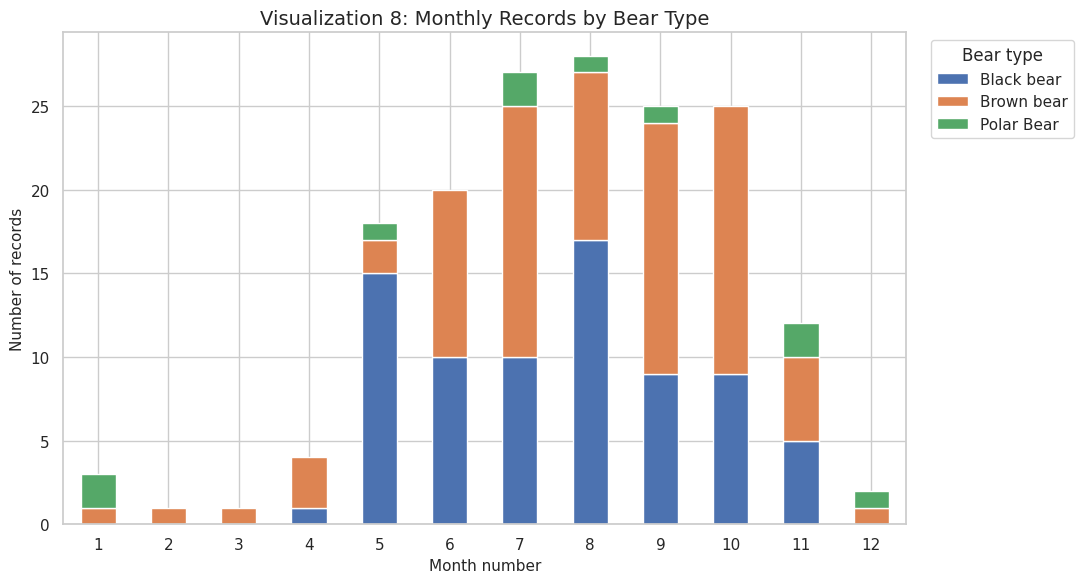

Caption: The stacked bars show how each bear type contributes to the monthly record counts.


In [20]:
if "incident_month" in plot_df.columns and "Type of bear" in plot_df.columns:
    month_bear = plot_df.dropna(subset=["incident_month", "Type of bear"]).copy()
    month_bear["incident_month"] = month_bear["incident_month"].astype(int)
    if not month_bear.empty:
        pivot = pd.crosstab(month_bear["incident_month"], month_bear["Type of bear"]).reindex(range(1, 13), fill_value=0)
        ax = pivot.plot(kind="bar", stacked=True, figsize=(11, 6))
        ax.set_title("Visualization 8: Monthly Records by Bear Type")
        ax.set_xlabel("Month number")
        ax.set_ylabel("Number of records")
        ax.legend(title="Bear type", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()
        print("Caption: The stacked bars show how each bear type contributes to the monthly record counts.")
    else:
        print("Skipped: No complete month and bear-type pairs.")
else:
    print("Skipped: Required columns unavailable.")

### Visualization 9 — Age and incident year

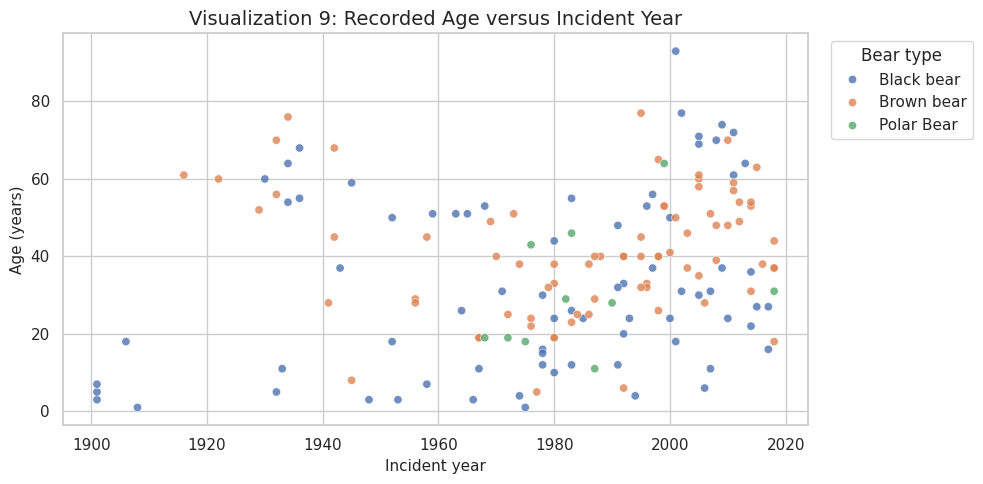

Caption: Each point represents a record with a valid age and year; the plot helps inspect coverage and broad patterns over time.


In [21]:
if "age" in plot_df.columns and "incident_year" in plot_df.columns:
    scatter_df = plot_df[["age", "incident_year", "Type of bear"]].copy()
    scatter_df["age"] = pd.to_numeric(scatter_df["age"], errors="coerce")
    scatter_df["incident_year"] = pd.to_numeric(scatter_df["incident_year"], errors="coerce")
    scatter_df = scatter_df.dropna(subset=["age", "incident_year"])
    if not scatter_df.empty:
        plt.figure(figsize=(10, 5))
        sns.scatterplot(data=scatter_df, x="incident_year", y="age", hue="Type of bear", alpha=0.8)
        plt.title("Visualization 9: Recorded Age versus Incident Year")
        plt.xlabel("Incident year")
        plt.ylabel("Age (years)")
        plt.legend(title="Bear type", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()
        print("Caption: Each point represents a record with a valid age and year; the plot helps inspect coverage and broad patterns over time.")
    else:
        print("Skipped: No complete age and year pairs.")
else:
    print("Skipped: Required columns unavailable.")

### Visualization 10 — Incident flags

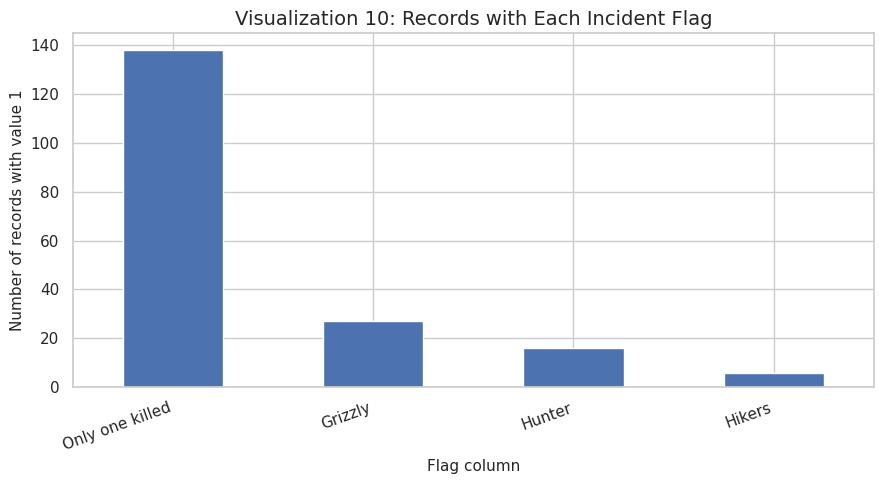

Caption: This chart counts records marked with value 1 in each supplied binary flag; definitions follow the source file's column labels.


In [22]:
flag_cols = [c for c in ["Hunter", "Grizzly", "Hikers", "Only one killed"] if c in plot_df.columns]
if flag_cols:
    flag_counts = {}
    for col in flag_cols:
        values = pd.to_numeric(plot_df[col], errors="coerce")
        flag_counts[col] = int((values == 1).sum())
    flag_series = pd.Series(flag_counts).sort_values(ascending=False)
    ax = flag_series.plot(kind="bar", figsize=(9, 5))
    ax.set_title("Visualization 10: Records with Each Incident Flag")
    ax.set_xlabel("Flag column")
    ax.set_ylabel("Number of records with value 1")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
    print("Caption: This chart counts records marked with value 1 in each supplied binary flag; definitions follow the source file's column labels.")
else:
    print("Skipped: No incident-flag columns are available.")

## Extra plots — added beyond the flowchart (rubric coverage)

Four extra plots cover the required types that Boxes 12 does not: a missingness plot, a correlation heatmap, a distribution comparison with a pairplot, and a PCA projection. They reuse `df_clean` and `df_model` and do not change any earlier cell.

### Visualization 11 — Missingness map (after type conversion)

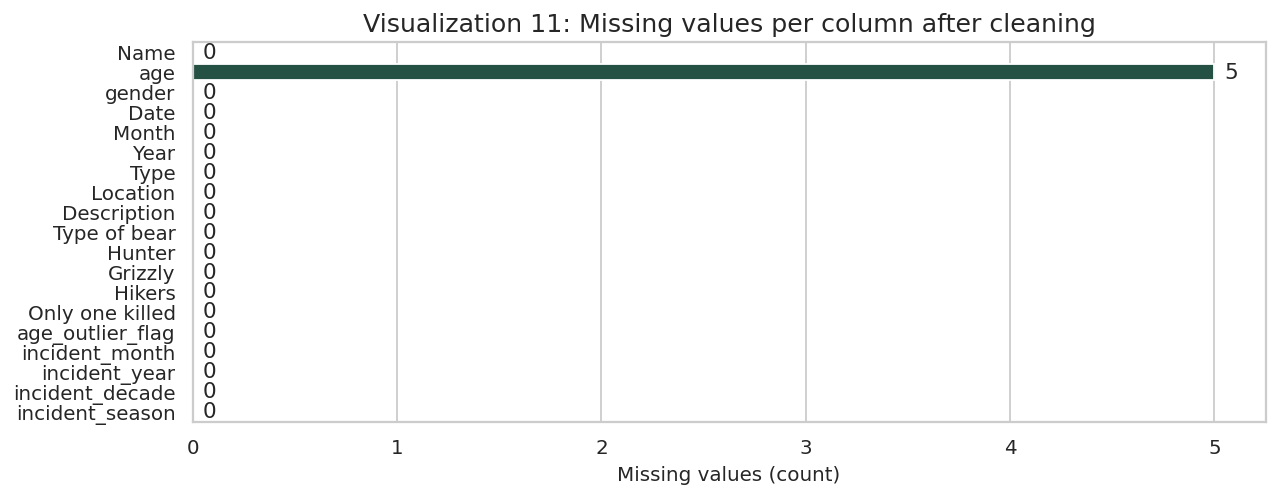

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
miss = df_clean.isna().sum()
sns.barplot(x=miss.values, y=miss.index, color="#1d5846", ax=ax)
ax.set_title("Visualization 11: Missing values per column after cleaning")
ax.set_xlabel("Missing values (count)"); ax.set_ylabel("")
for p in ax.patches: ax.text(p.get_width()+0.05, p.get_y()+p.get_height()/2, int(p.get_width()), va="center")
plt.tight_layout(); plt.show()
print("Caption: Only age has missing values after cleaning (5 non-numeric entries such as '10 months'); other columns are complete.")

### Visualization 12 — Correlation heatmap (numeric fields)

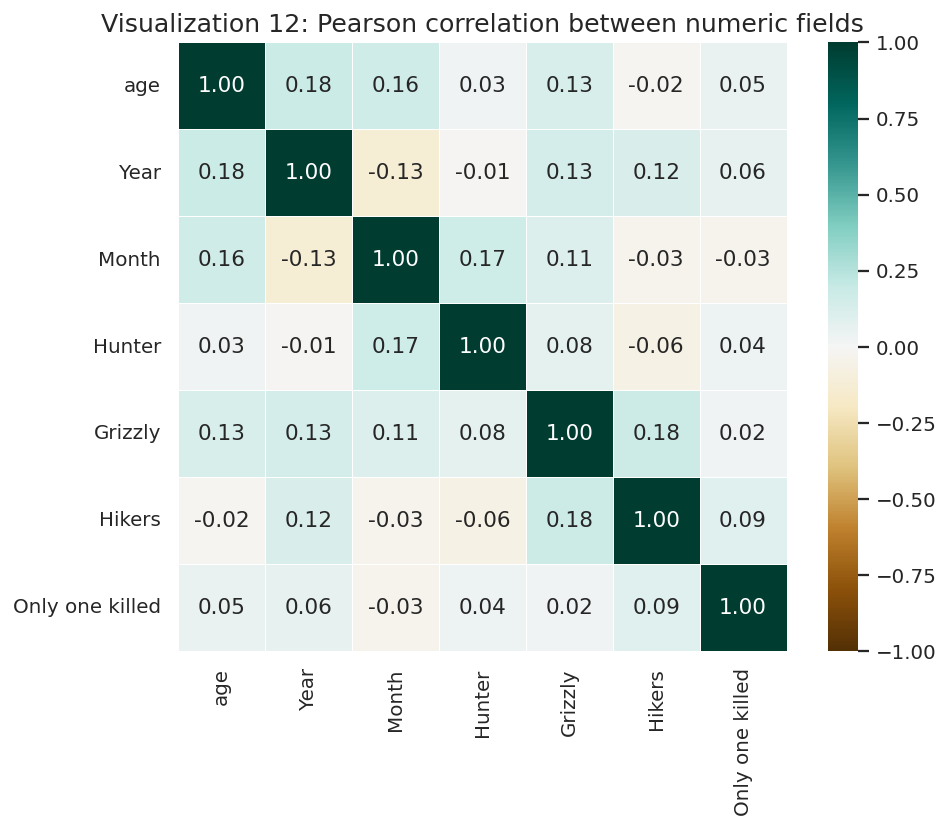

In [ ]:
num_cols = ["age", "Year", "Month", "Hunter", "Grizzly", "Hikers", "Only one killed"]
corr = df_clean[num_cols].apply(pd.to_numeric, errors="coerce").corr(method="pearson")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="BrBG", vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Visualization 12: Pearson correlation between numeric fields")
plt.tight_layout(); plt.show()
print("Caption: Correlations are computed on pairwise complete rows. Values near zero mean no linear relation; they do not show causes.")

### Visualization 13 — Age distribution (KDE) by bear type and pairplot

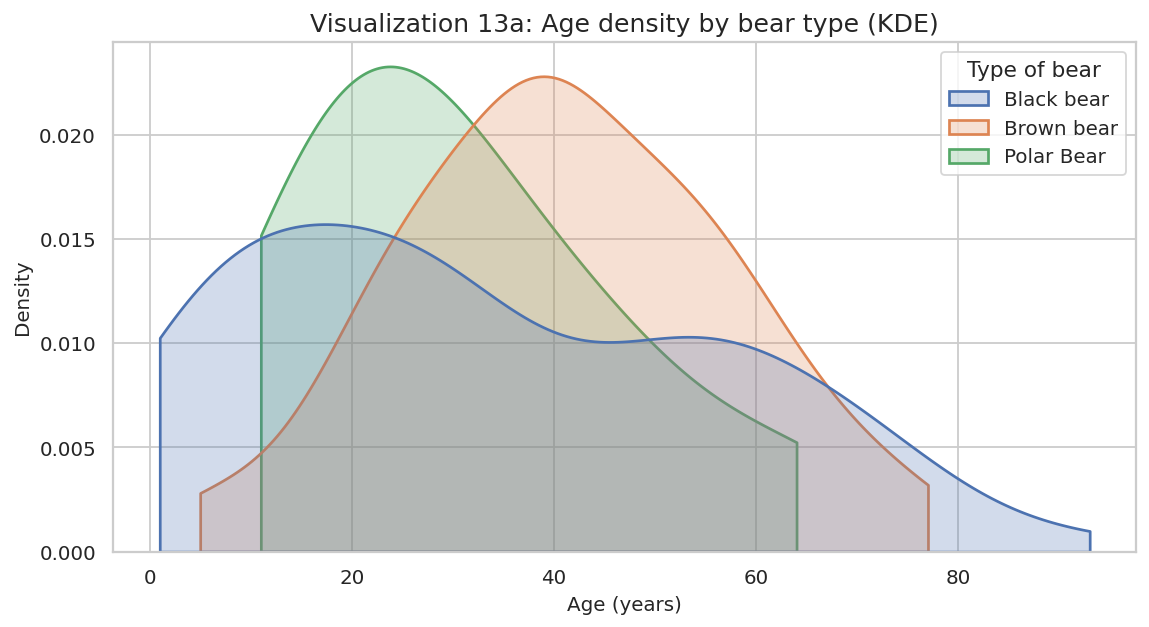

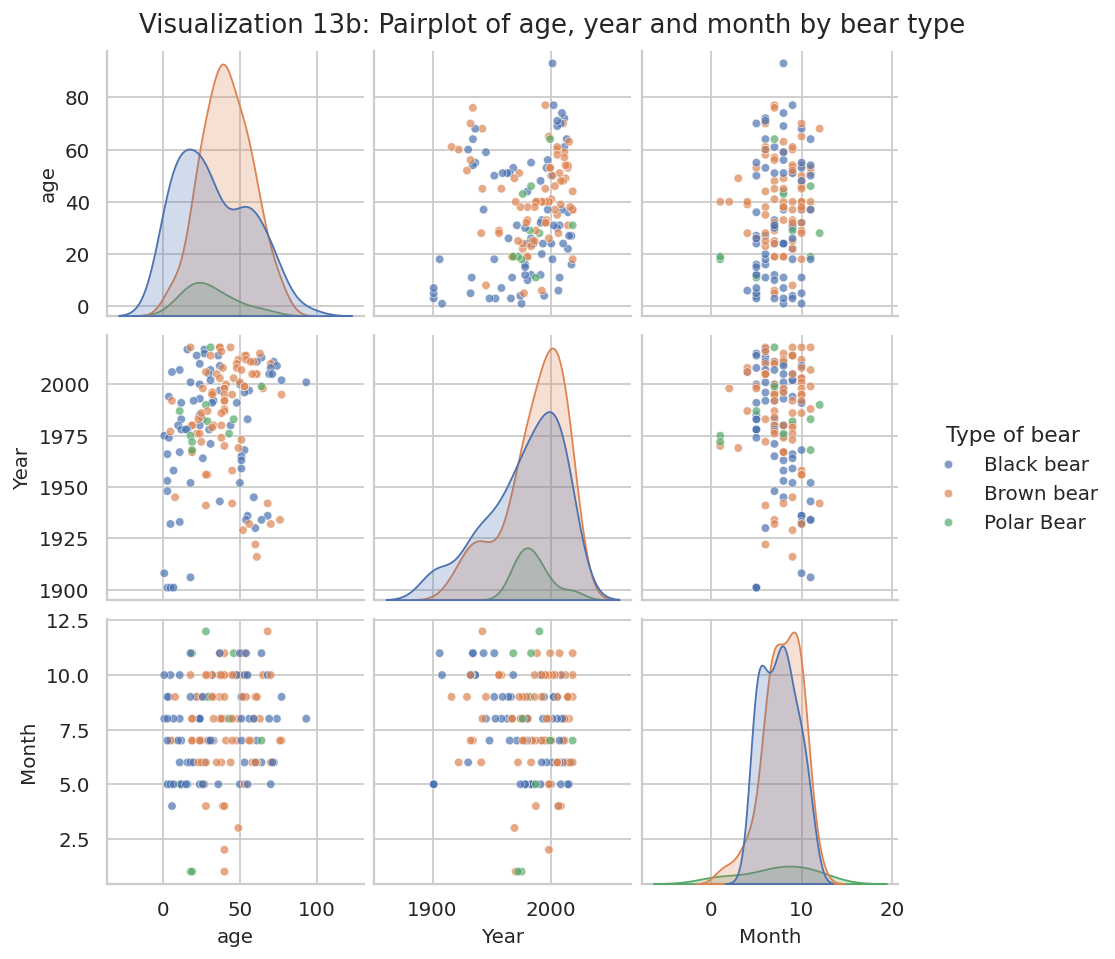

In [ ]:
kde_df = df_clean[["age", "Type of bear"]].copy()
kde_df["age"] = pd.to_numeric(kde_df["age"], errors="coerce")
kde_df = kde_df.dropna().astype({"Type of bear": str})
plt.figure(figsize=(9, 5))
sns.kdeplot(data=kde_df, x="age", hue="Type of bear", common_norm=False, fill=True, alpha=.25, linewidth=1.5, cut=0)
plt.title("Visualization 13a: Age density by bear type (KDE)")
plt.xlabel("Age (years)"); plt.ylabel("Density")
plt.tight_layout(); plt.show()
print("Caption: Kernel density curves show where each bear type's recorded ages concentrate. Samples are small for polar bears.")
pp = df_clean[["age", "Year", "Month", "Type of bear"]].copy()
pp["age"] = pd.to_numeric(pp["age"], errors="coerce")
pp = pp.dropna(subset=["age"]).astype({"Type of bear": str})
g = sns.pairplot(pp, vars=["age", "Year", "Month"], hue="Type of bear", height=2.4, plot_kws={"alpha": .7, "s": 22})
g.fig.suptitle("Visualization 13b: Pairplot of age, year and month by bear type", y=1.02)
plt.show()
print("Caption: Off-diagonal panels show pairwise relations; diagonal panels show each variable's distribution.")

### Visualization 14 — PCA of the model-ready features

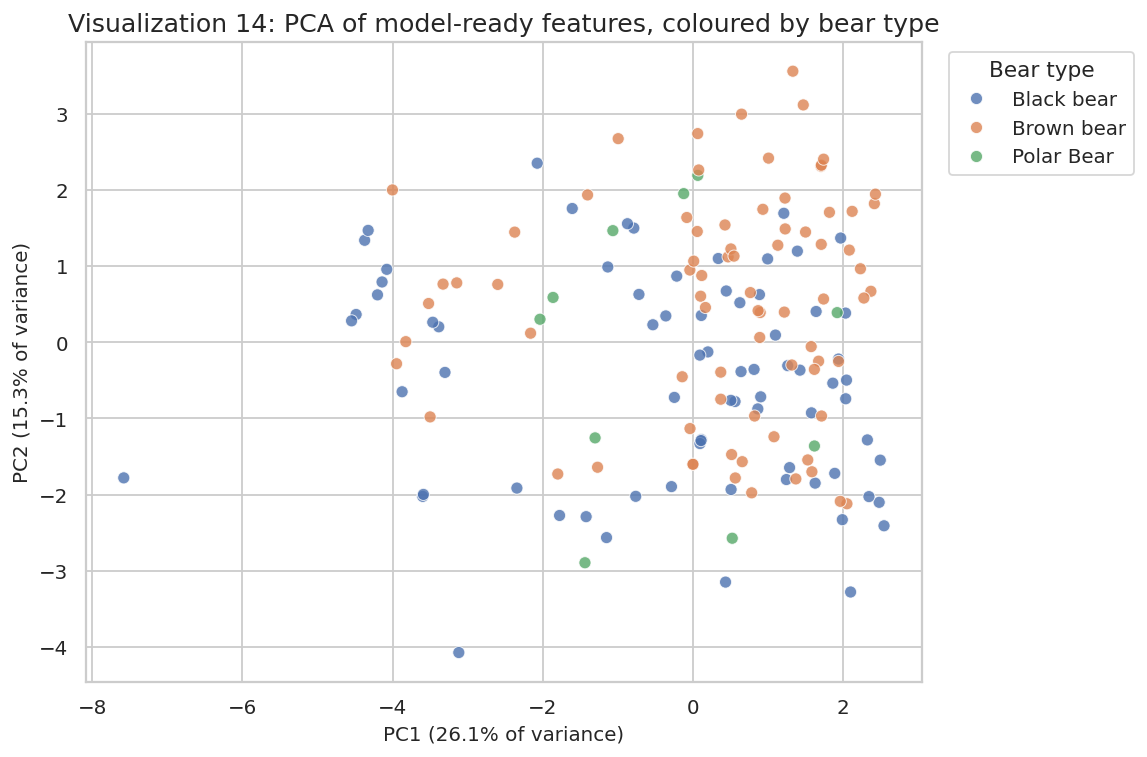

In [ ]:
from sklearn.decomposition import PCA
pca_df = df_model.dropna(subset=["age"]).copy()
bear_cols = [c for c in pca_df.columns if c.startswith("Type of bear_")]
feat_cols = [c for c in pca_df.columns if c not in bear_cols and c != "age_scaled" and c != "incident_season"]
X = pca_df[feat_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
X_std = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=0)
coords = pca.fit_transform(X_std)
labels = pca_df[bear_cols].idxmax(axis=1).str.replace("Type of bear_", "", regex=False)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels.values, alpha=.8, s=45)
plt.title("Visualization 14: PCA of model-ready features, coloured by bear type")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% of variance)")
plt.legend(title="Bear type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
print("Caption: Two components capture the spread of the encoded features. Clusters are weak, so bear type is not cleanly separated by these features.")

## End

This project uses the uploaded `north_america_bear_killings.csv` file. The workflow inspects the real columns, standardizes text, handles the missing gender label transparently, removes only exact duplicate rows if present, converts age and date fields to appropriate types, flags potential age outliers without automatically deleting historical records, and derives date-based features.

Two outputs are saved: a readable cleaned dataset and a separate model-ready table with selected categorical variables encoded and age scaled when possible. The ten visualizations summarize bear type, timing, age, setting, recorded gender, and incident flags. Interpretations should remain descriptive: the file contains recorded cases, not population denominators, so charts alone cannot establish the risk of an attack or causal relationships.

**Important limitation:** The uploaded CSV does not provide a verifiable publisher/source URL or a data dictionary. Interpret binary flags according to the source file's labels and verify their definitions against the original source before using them for high-stakes conclusions.